<img src="./images/two_stage_nn_with_scalers.png" alt="Model shape" width="600" />


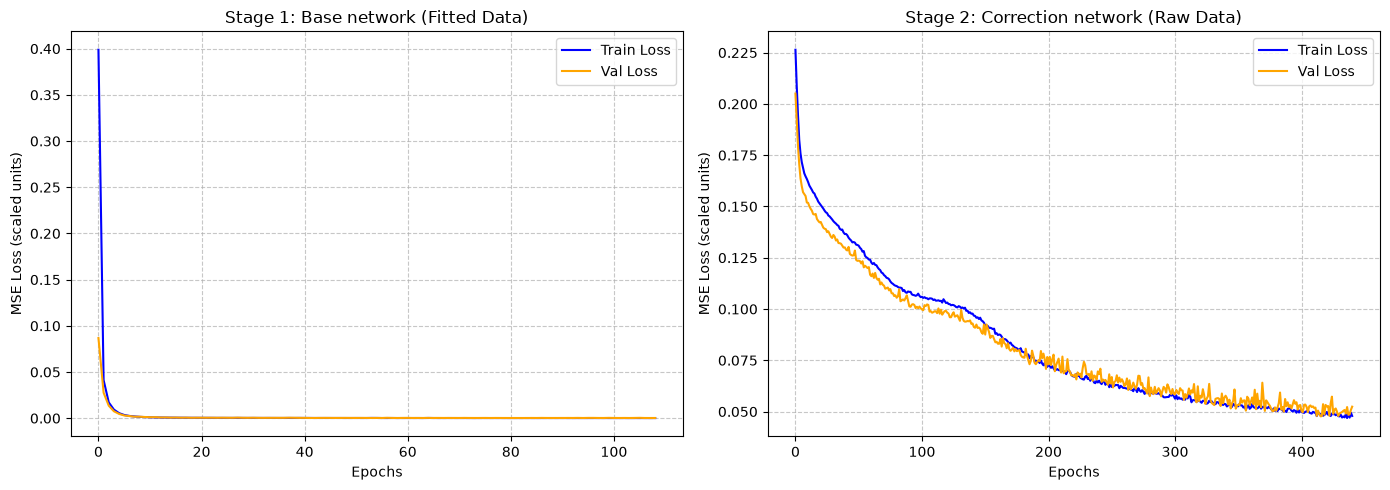

In [1]:
import joblib
import matplotlib.pyplot as plt

# Load the saved histories
history_fit = joblib.load('base_history.joblib')
history_raw = joblib.load('correction_history.joblib')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Phase 1 (Fitted Data)
ax1.plot(history_fit['loss'], label='Train Loss', color='blue')
ax1.plot(history_fit['val_loss'], label='Val Loss', color='orange')
ax1.set_title('Stage 1: Base network (Fitted Data)')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('MSE Loss (scaled units)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

# Plot Phase 2 (Raw Data)
ax2.plot(history_raw['loss'], label='Train Loss', color='blue')
ax2.plot(history_raw['val_loss'], label='Val Loss', color='orange')
ax2.set_title('Stage 2: Correction network (Raw Data)')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('MSE Loss (scaled units)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [2]:
import numpy as np
import pickle

train_test_data = np.load('train_test_data.npz')
scalerX = pickle.load(open('scalerX.pkl', 'rb'))
scalery = pickle.load(open('scalery.pkl', 'rb'))
d = pickle.load(open('scaler_r.pkl', 'rb'))
scaler_r, S = (d['scaler_r'], d['S']) if isinstance(d, dict) else (d, 1e-2)
print(f"Two-stage floor S = {S:g}")

Xraw_selected_train = train_test_data['Xraw_selected_train']
Xraw_selected_train_scaled = scalerX.transform(Xraw_selected_train)  
Xraw_selected_test = train_test_data['Xraw_selected_test']
Xraw_selected_test_scaled = scalerX.transform(Xraw_selected_test)
Xraw_selected_val = train_test_data['Xraw_selected_val']
Xraw_selected_val_scaled = scalerX.transform(Xraw_selected_val)

yraw_selected_train = train_test_data['yraw_selected_train']
yraw_selected_train_scaled = scalery.transform(yraw_selected_train.reshape(-1, 1))
yraw_selected_test = train_test_data['yraw_selected_test']
yraw_selected_test_scaled = scalery.transform(yraw_selected_test.reshape(-1, 1))
yraw_selected_val = train_test_data['yraw_selected_val']
yraw_selected_val_scaled = scalery.transform(yraw_selected_val.reshape(-1, 1))

Xfit_selected_train = train_test_data['Xfit_selected_train']
Xfit_selected_train_scaled = scalerX.transform(Xfit_selected_train)
Xfit_selected_test = train_test_data['Xfit_selected_test']
Xfit_selected_test_scaled = scalerX.transform(Xfit_selected_test)    
Xfit_selected_val = train_test_data['Xfit_selected_val']
Xfit_selected_val_scaled = scalerX.transform(Xfit_selected_val)

yfit_selected_train = train_test_data['yfit_selected_train']
yfit_selected_train_scaled = scalery.transform(yfit_selected_train.reshape(-1, 1))
yfit_selected_test = train_test_data['yfit_selected_test']
yfit_selected_test_scaled = scalery.transform(yfit_selected_test.reshape(-1, 1))
yfit_selected_val = train_test_data['yfit_selected_val']
yfit_selected_val_scaled = scalery.transform(yfit_selected_val.reshape(-1, 1)) 

Two-stage floor S = 0.01


Raw Min and Max j1 (Train): 0.0 16.0
Raw Min and Max j2 (Train): 0.0 23.0
Raw Min and Max j1  (Test): 0.0 16.0
Raw Min and Max j2  (Test): 0.0 23.0
Raw Min and Max j1  (Val): 0.0 16.0
Raw Min and Max j2  (Val): 0.0 23.0


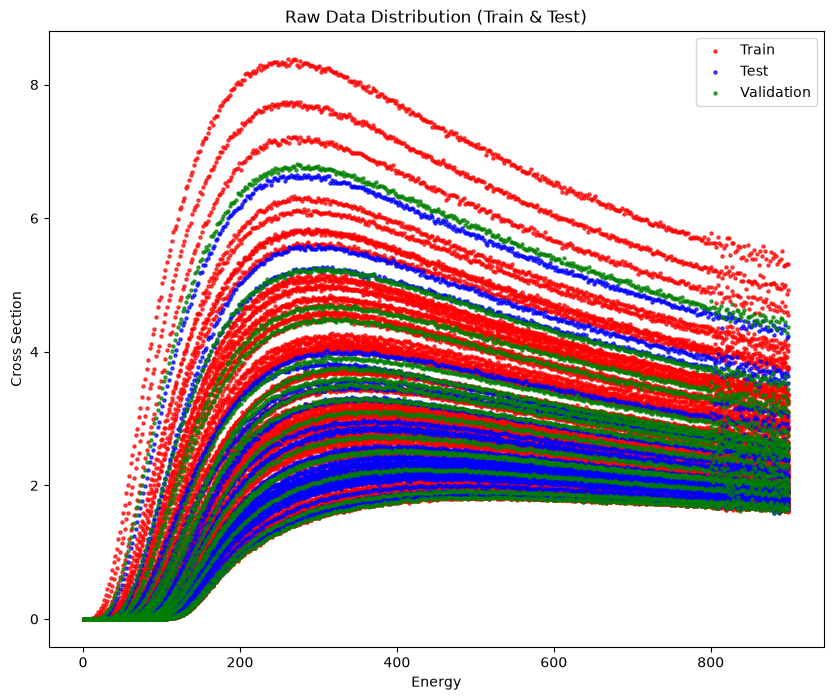

In [3]:
size=5
j1s_raw_train = Xraw_selected_train[:, 0]
j2s_raw_train = Xraw_selected_train[:, 1]
print("Raw Min and Max j1 (Train):", min(j1s_raw_train), max(j1s_raw_train))
print("Raw Min and Max j2 (Train):", min(j2s_raw_train), max(j2s_raw_train))
j1s_raw_test = Xraw_selected_test[:, 0]
j2s_raw_test = Xraw_selected_test[:, 1]
print("Raw Min and Max j1  (Test):", min(j1s_raw_test), max(j1s_raw_test))
print("Raw Min and Max j2  (Test):", min(j2s_raw_test), max(j2s_raw_test)) 
j1s_raw_val = Xraw_selected_val[:, 0]
j2s_raw_val = Xraw_selected_val[:, 1]
print("Raw Min and Max j1  (Val):", min(j1s_raw_val), max(j1s_raw_val))
print("Raw Min and Max j2  (Val):", min(j2s_raw_val), max(j2s_raw_val))

# Create boolean masks for filtering
mask_train = np.isin(Xraw_selected_train[:, 0], j1s_raw_train) & np.isin(
    Xraw_selected_train[:, 1], j2s_raw_train
)
mask_test = np.isin(Xraw_selected_test[:, 0], j1s_raw_test) & np.isin(
    Xraw_selected_test[:, 1], j2s_raw_test
)
mask_val = np.isin(Xraw_selected_val[:, 0], j1s_raw_val) & np.isin(
    Xraw_selected_val[:, 1], j2s_raw_val
)

plt.figure(figsize=(10, 8))

plt.scatter(
    Xraw_selected_train[mask_train, 2],
    yraw_selected_train[mask_train],
    s=size,
    label="Train",
    color="red",
    alpha=0.7,
)
plt.scatter(
    Xraw_selected_test[mask_test, 2],
    yraw_selected_test[mask_test],
    s=size,
    label="Test",
    color="blue",
    alpha=0.7,
)
plt.scatter(
    Xraw_selected_val[mask_val, 2],
    yraw_selected_val[mask_val],
    s=size,
    label="Validation",
    color="green",
    alpha=0.7,
)

plt.xlabel("Energy")
plt.ylabel("Cross Section")
plt.title("Raw Data Distribution (Train & Test)")
plt.legend()
plt.show()

In [4]:
import plotly.graph_objects as go

fig = go.Figure()

# Train points
fig.add_trace(go.Scatter3d(
    x=Xraw_selected_train[:, 0],
    y=Xraw_selected_train[:, 2],
    z=yraw_selected_train,
    mode='markers',
    marker=dict(size=3, color='red', opacity=0.6),
    name='Train'
))

# Test points
fig.add_trace(go.Scatter3d(
    x=Xraw_selected_test[:, 0],
    y=Xraw_selected_test[:, 2],
    z=yraw_selected_test,
    mode='markers',
    marker=dict(size=3, color='blue', opacity=0.6),
    name='Test'
))

fig.add_trace(go.Scatter3d(
    x=Xraw_selected_val[:, 0],
    y=Xraw_selected_val[:, 2],
    z=yraw_selected_val, 
    mode='markers',
    marker=dict(size=3, color='green', opacity=0.6),
    name='Validation'
))

# Set dimensions and layout
fig.update_layout(
    width=1200,   # Set width
    height=900,   # Set height
    title="Interactive 3D Data Distribution",
    scene=dict(
        xaxis_title='j1',
        yaxis_title='Energy',
        zaxis_title='Cross Section'
    )
)

fig.show()


Fitted Min and Max j1 (Train): 0.0 16.0
Fitted Min and Max j2 (Train): 0.0 23.0
Fitted Min and Max j1  (Test): 0.0 16.0
Fitted Min and Max j2  (Test): 0.0 23.0
Fitted Min and Max j1  (Val): 0.0 16.0
Fitted Min and Max j2  (Val): 0.0 23.0


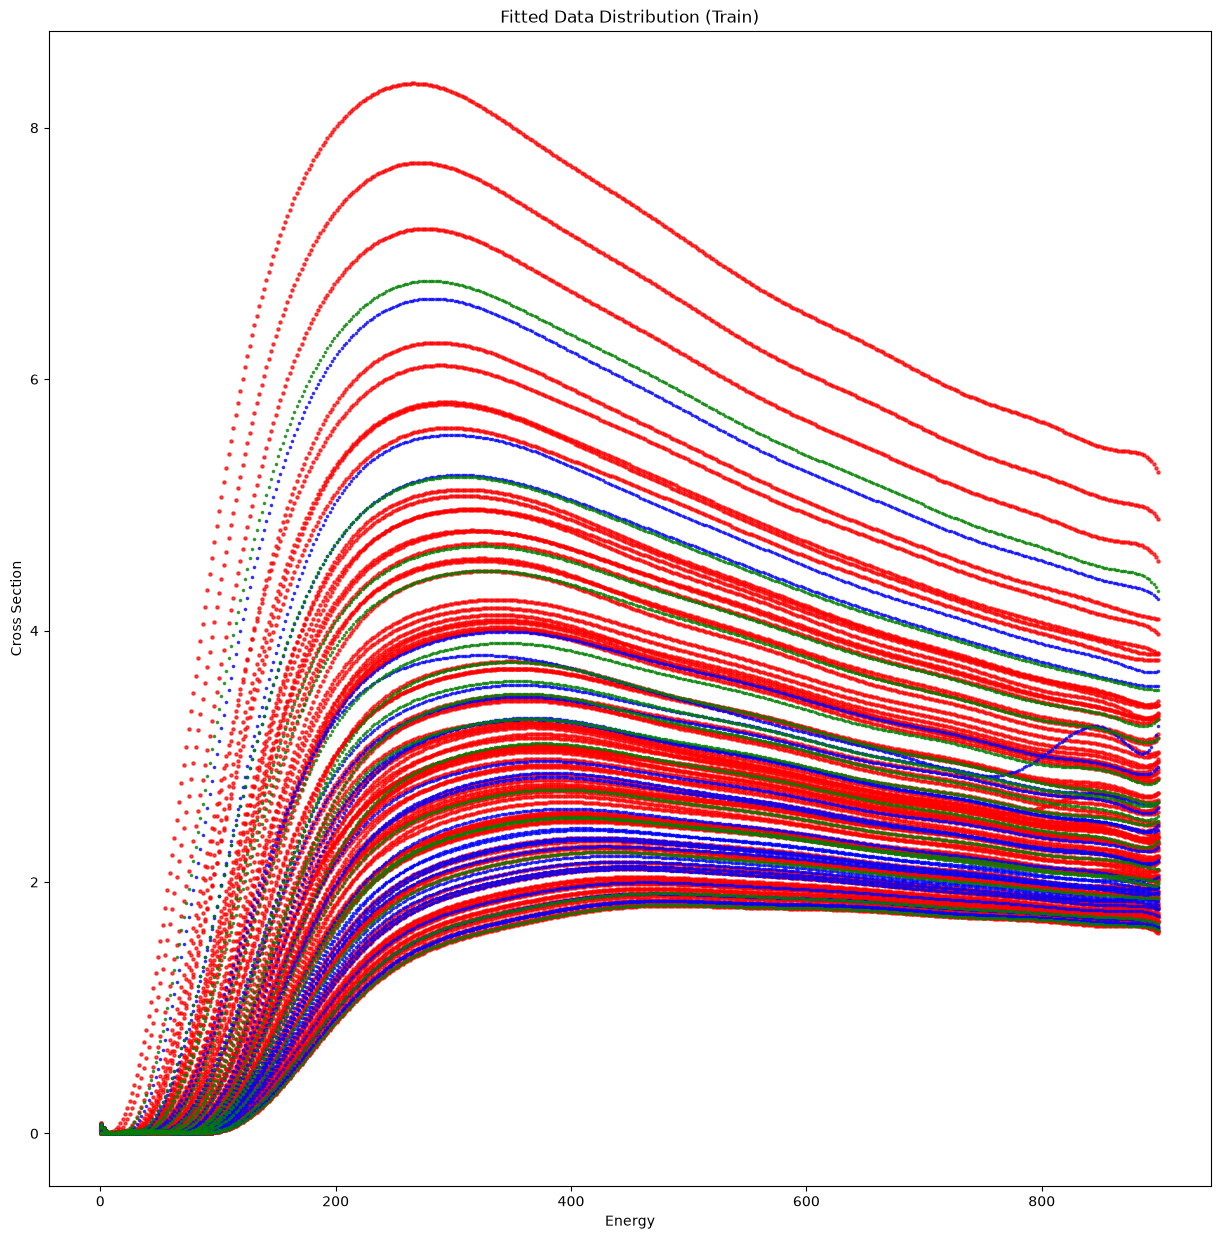

In [5]:
j1s_fit_train = Xfit_selected_train[:, 0]
j2s_fit_train = Xfit_selected_train[:, 1]
print("Fitted Min and Max j1 (Train):", min(j1s_fit_train), max(j1s_fit_train))
print("Fitted Min and Max j2 (Train):", min(j2s_fit_train), max(j2s_fit_train))
j1s_fit_test = Xfit_selected_test[:, 0]
j2s_fit_test = Xfit_selected_test[:, 1]
print("Fitted Min and Max j1  (Test):", min(j1s_fit_test), max(j1s_fit_test))
print("Fitted Min and Max j2  (Test):", min(j2s_fit_test), max(j2s_fit_test))
j1s_fit_val = Xfit_selected_val[:, 0]
j2s_fit_val = Xfit_selected_val[:, 1]
print("Fitted Min and Max j1  (Val):", min(j1s_fit_val), max(j1s_fit_val))
print("Fitted Min and Max j2  (Val):", min(j2s_fit_val), max(j2s_fit_val))

plt.figure(figsize=(15, 15))
for j1 in np.unique(j1s_fit_train):
    for j2 in np.unique(j2s_fit_train):
        selectedindex = np.where((Xfit_selected_train[:, 0] == j1) & (Xfit_selected_train[:, 1] == j2))
        Xfit_subset = Xfit_selected_train[selectedindex]
        efit = Xfit_subset[:, 2]
        yfit_subset = yfit_selected_train[selectedindex]
        plt.scatter(efit, yfit_subset, s=size, label="Train", color='red', alpha=0.7)
for j1 in np.unique(j1s_fit_test):
    for j2 in np.unique(j2s_fit_test):
        selectedindex = np.where((Xfit_selected_test[:, 0] == j1) & (Xfit_selected_test[:, 1] == j2))
        Xfit_subset = Xfit_selected_test[selectedindex]
        efit = Xfit_subset[:, 2]
        yfit_subset = yfit_selected_test[selectedindex]
        plt.scatter(efit, yfit_subset, s=size/2, label="Test", color='blue', alpha=0.7)
for j1 in np.unique(j1s_fit_val):
    for j2 in np.unique(j2s_fit_val):
        selectedindex = np.where((Xfit_selected_val[:, 0] == j1) & (Xfit_selected_val[:, 1] == j2))
        Xfit_subset = Xfit_selected_val[selectedindex]
        efit = Xfit_subset[:, 2]
        yfit_subset = yfit_selected_val[selectedindex]
        plt.scatter(efit, yfit_subset, s=size/2, label="Validation", color='green', alpha=0.7)
plt.xlabel('Energy')
plt.ylabel('Cross Section')  
plt.title('Fitted Data Distribution (Train)')
plt.show()

In [6]:
import plotly.graph_objects as go

fig = go.Figure()

# Train points
fig.add_trace(go.Scatter3d(
    x=Xfit_selected_train[:, 0],
    y=Xfit_selected_train[:, 2],
    z=yfit_selected_train,
    mode='markers',
    marker=dict(size=3, color='red', opacity=0.6),
    name='Train'
))

# Test points
fig.add_trace(go.Scatter3d(
    x=Xfit_selected_test[:, 0],
    y=Xfit_selected_test[:, 2],
    z=yfit_selected_test,
    mode='markers',
    marker=dict(size=3, color='blue', opacity=0.6),
    name='Test'
))

fig.add_trace(go.Scatter3d(
    x=Xfit_selected_val[:, 0],
    y=Xfit_selected_val[:, 2],
    z=yfit_selected_val,
    mode='markers',
    marker=dict(size=3, color='green', opacity=0.6),
    name='Validation'
))

# Set dimensions and layout
fig.update_layout(
    width=1200,   # Set width
    height=900,   # Set height
    title="Interactive 3D Data Distribution",
    scene=dict(
        xaxis_title='j1',
        yaxis_title='Energy',
        zaxis_title='Cross Section'
    )
)

fig.show()


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pretrained_model = joblib.load('base_model.joblib')   # stage 1: base network
print("Pre-trained model loaded successfully.")
print("Pre-trained model summary:")
pretrained_model.summary()

pretrained_predraw_scaled_test = pretrained_model.predict(Xraw_selected_test_scaled)
pretrained_predraw_scaled_train = pretrained_model.predict(Xraw_selected_train_scaled)
pretrained_predraw_scaled_val = pretrained_model.predict(Xraw_selected_val_scaled)
pretrained_predraw_test = scalery.inverse_transform(\
    pretrained_predraw_scaled_test.reshape(-1, 1))
pretrained_predraw_train = scalery.inverse_transform(\
    pretrained_predraw_scaled_train.reshape(-1, 1))
pretrained_predraw_val = scalery.inverse_transform(\
    pretrained_predraw_scaled_val.reshape(-1, 1))
pretrained_rmseraw_train = np.sqrt(np.mean((yraw_selected_train - pretrained_predraw_train.flatten()) ** 2))
pretrained_rmseraw_test = np.sqrt(np.mean((yraw_selected_test - pretrained_predraw_test.flatten()) ** 2))
pretrained_rmseraw_val = np.sqrt(np.mean((yraw_selected_val - pretrained_predraw_val.flatten()) ** 2))
pretrained_maeraw_train = np.mean(np.abs(yraw_selected_train - pretrained_predraw_train.flatten()))
pretrained_maeraw_test = np.mean(np.abs(yraw_selected_test - pretrained_predraw_test.flatten()))
pretrained_maeraw_val = np.mean(np.abs(yraw_selected_val - pretrained_predraw_val.flatten()))
pretrained_r2raw_train = 1 - np.sum((yraw_selected_train - pretrained_predraw_train.flatten()) ** 2) \
    / np.sum((yraw_selected_train - np.mean(yraw_selected_train)) ** 2)
pretrained_r2raw_test = 1 - np.sum((yraw_selected_test - pretrained_predraw_test.flatten()) ** 2) \
    / np.sum((yraw_selected_test - np.mean(yraw_selected_test)) ** 2)
pretrained_r2raw_val = 1 - np.sum((yraw_selected_val - pretrained_predraw_val.flatten()) ** 2) \
    / np.sum((yraw_selected_val - np.mean(yraw_selected_val)) ** 2)

pretrained_predfit_scaled = pretrained_model.predict(Xfit_selected_test_scaled)
pretrained_predfit_test = scalery.inverse_transform(pretrained_predfit_scaled.reshape(-1, 1))
pretrained_predfit_scaled_train = pretrained_model.predict(Xfit_selected_train_scaled)
pretrained_predfit_train = scalery.inverse_transform(pretrained_predfit_scaled_train.reshape(-1,   1))
pretrained_predfit_scaled_val = pretrained_model.predict(Xfit_selected_val_scaled)
pretrained_predfit_val = scalery.inverse_transform(pretrained_predfit_scaled_val.reshape(-1, 1))

pretrained_rmsefit_train = np.sqrt(np.mean((yfit_selected_train - pretrained_predfit_train.flatten()) ** 2))
pretrained_rmsefit_test = np.sqrt(np.mean((yfit_selected_test - pretrained_predfit_test.flatten()) ** 2))
pretrained_rmsefit_val = np.sqrt(np.mean((yfit_selected_val - pretrained_predfit_val.flatten()) ** 2))
pretrained_maefit_train = np.mean(np.abs(yfit_selected_train - pretrained_predfit_train.flatten()))
pretrained_maefit_test = np.mean(np.abs(yfit_selected_test - pretrained_predfit_test.flatten()))
pretrained_maefit_val = np.mean(np.abs(yfit_selected_val - pretrained_predfit_val.flatten()))
pretrained_r2fit_train = 1 - np.sum((yfit_selected_train - pretrained_predfit_train.flatten()) ** 2) \
    / np.sum((yfit_selected_train - np.mean(yfit_selected_train)) ** 2)
pretrained_r2fit_test = 1 - np.sum((yfit_selected_test - pretrained_predfit_test.flatten()) ** 2) \
    / np.sum((yfit_selected_test - np.mean(yfit_selected_test)) ** 2)
pretrained_r2fit_val = 1 - np.sum((yfit_selected_val - pretrained_predfit_val.flatten()) ** 2) \
    / np.sum((yfit_selected_val - np.mean(yfit_selected_val)) ** 2)

I0000 00:00:1793027226.024767 3960217 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793027226.058680 3960217 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793027226.770554 3960217 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1793027226.928761 3960217 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries men

Pre-trained model loaded successfully.
Pre-trained model summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,445 (52.52 KB)

 Trainable params: 4,481 (17.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,964 (35.02 KB)

366/366 ━━━━━━━━━━━━━━━━━━━━ 0s 307us/step
1238/1238 ━━━━━━━━━━━━━━━━━━━━ 0s 264us/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 263us/step
366/366 ━━━━━━━━━━━━━━━━━━━━ 0s 261us/step
1238/1238 ━━━━━━━━━━━━━━━━━━━━ 0s 276us/step
225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 272us/step


In [8]:
corr_model = joblib.load('correction_model.joblib')   # stage 2: correction network
print("Correction model summary:")
corr_model.summary()

def predict_two_stage(X_scaled):
    """Base + correction, in linear units, shape (n, 1) like the other predictions."""
    y_base = scalery.inverse_transform(pretrained_model.predict(X_scaled, verbose=0).reshape(-1, 1))
    delta = scaler_r.inverse_transform(corr_model.predict(X_scaled, verbose=0).reshape(-1, 1))
    return np.clip(y_base + (y_base + S) * delta, 0, None)

fine_tuned_predraw_test  = predict_two_stage(Xraw_selected_test_scaled)
fine_tuned_predraw_train = predict_two_stage(Xraw_selected_train_scaled)
fine_tuned_predraw_val   = predict_two_stage(Xraw_selected_val_scaled)
fine_tuned_rmseraw_train = np.sqrt(np.mean((yraw_selected_train - fine_tuned_predraw_train.flatten()) ** 2))
fine_tuned_rmseraw_test = np.sqrt(np.mean((yraw_selected_test - fine_tuned_predraw_test.flatten()) ** 2))
fine_tuned_rmseraw_val = np.sqrt(np.mean((yraw_selected_val - fine_tuned_predraw_val.flatten()) ** 2))

fine_tuned_maeraw_train = np.mean(np.abs(yraw_selected_train - fine_tuned_predraw_train.flatten()))
fine_tuned_maeraw_test = np.mean(np.abs(yraw_selected_test - fine_tuned_predraw_test.flatten()))
fine_tuned_maeraw_val = np.mean(np.abs(yraw_selected_val - fine_tuned_predraw_val.flatten()))
fine_tuned_r2raw_train = 1 - np.sum((yraw_selected_train - fine_tuned_predraw_train.flatten()) ** 2) \
    / np.sum((yraw_selected_train - np.mean(yraw_selected_train)) ** 2)
fine_tuned_r2raw_test = 1 - np.sum((yraw_selected_test - fine_tuned_predraw_test.flatten()) ** 2) \
    / np.sum((yraw_selected_test - np.mean(yraw_selected_test)) ** 2)
fine_tuned_r2raw_val = 1 - np.sum((yraw_selected_val - fine_tuned_predraw_val.flatten()) ** 2) \
    / np.sum((yraw_selected_val - np.mean(yraw_selected_val)) ** 2)                                      

fine_tuned_predfit_test  = predict_two_stage(Xfit_selected_test_scaled)
fine_tuned_predfit_train = predict_two_stage(Xfit_selected_train_scaled)
fine_tuned_predfit_val   = predict_two_stage(Xfit_selected_val_scaled)

fine_tuned_rmsefit_train = np.sqrt(np.mean((yfit_selected_train - fine_tuned_predfit_train.flatten()) ** 2))
fine_tuned_rmsefit_test = np.sqrt(np.mean((yfit_selected_test - fine_tuned_predfit_test.flatten()) ** 2))
fine_tuned_rmsefit_val = np.sqrt(np.mean((yfit_selected_val - fine_tuned_predfit_val.flatten()) ** 2))
fine_tuned_maefit_train = np.mean(np.abs(yfit_selected_train - fine_tuned_predfit_train.flatten()))
fine_tuned_maefit_test = np.mean(np.abs(yfit_selected_test - fine_tuned_predfit_test.flatten()))
fine_tuned_maefit_val = np.mean(np.abs(yfit_selected_val - fine_tuned_predfit_val.flatten()))
fine_tuned_r2fit_train = 1 - np.sum((yfit_selected_train - fine_tuned_predfit_train.flatten()) ** 2) \
    / np.sum((yfit_selected_train - np.mean(yfit_selected_train)) ** 2)
fine_tuned_r2fit_test = 1 - np.sum((yfit_selected_test - fine_tuned_predfit_test.flatten()) ** 2) \
    / np.sum((yfit_selected_test - np.mean(yfit_selected_test)) ** 2)
fine_tuned_r2fit_val = 1 - np.sum((yfit_selected_val - fine_tuned_predfit_val.flatten()) ** 2) \
    / np.sum((yfit_selected_val - np.mean(yfit_selected_val)) ** 2)

Correction model summary:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,653 (14.27 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,436 (9.52 KB)

In [9]:
print("Model Performance on Raw Data:")
print(f"      Base Train RMSE: {pretrained_rmseraw_train:.4f}, Test RMSE: {pretrained_rmseraw_test:.4f}")
print(f" Two-stage Train RMSE: {fine_tuned_rmseraw_train:.4f}, Test RMSE: {fine_tuned_rmseraw_test:.4f}")
print(f"       Base Train MAE: {pretrained_maeraw_train:.4f},  Test MAE: {pretrained_maeraw_test:.4f}")
print(f"  Two-stage Train MAE: {fine_tuned_maeraw_train:.4f},  Test MAE: {fine_tuned_maeraw_test:.4f}")
print(f"        Base Train R2: {pretrained_r2raw_train:.4f},   Test R2: {pretrained_r2raw_test:.4f}")
print(f"   Two-stage Train R2: {fine_tuned_r2raw_train:.4f},   Test R2: {fine_tuned_r2raw_test:.4f}")

print("Model Performance on Fitted Data:")
print(f"      Base Train RMSE: {pretrained_rmsefit_train:.4f}, Test RMSE: {pretrained_rmsefit_test:.4f}")
print(f" Two-stage Train RMSE: {fine_tuned_rmsefit_train:.4f}, Test RMSE: {fine_tuned_rmsefit_test:.4f}")
print(f"       Base Train MAE: {pretrained_maefit_train:.4f},  Test MAE: {pretrained_maefit_test:.4f}")
print(f"  Two-stage Train MAE: {fine_tuned_maefit_train:.4f},  Test MAE: {fine_tuned_maefit_test:.4f}")
print(f"        Base Train R2: {pretrained_r2fit_train:.4f},   Test R2: {pretrained_r2fit_test:.4f}")
print(f"   Two-stage Train R2: {fine_tuned_r2fit_train:.4f},   Test R2: {fine_tuned_r2fit_test:.4f}")   

print("Model Performance on Validation Data:")
print(f"      Base Validation RMSE: {pretrained_rmseraw_val:.4f}, Fitted RMSE: {pretrained_rmsefit_val:.4f}")
print(f" Two-stage Validation RMSE: {fine_tuned_rmseraw_val:.4f}, Fitted RMSE: {fine_tuned_rmsefit_val:.4f}")
print(f"       Base Validation MAE: {pretrained_maeraw_val:.4f},  Fitted MAE: {pretrained_maefit_val:.4f}")
print(f"  Two-stage Validation MAE: {fine_tuned_maeraw_val:.4f},  Fitted MAE: {fine_tuned_maefit_val:.4f}")
print(f"        Base Validation R2: {pretrained_r2raw_val:.4f},   Fitted R2:    {pretrained_r2fit_val:.4f}")
print(f"   Two-stage Validation R2: {fine_tuned_r2raw_val:.4f},   Fitted R2:    {fine_tuned_r2fit_val:.4f}")

Model Performance on Raw Data:
      Base Train RMSE: 0.0289, Test RMSE: 0.1053
 Two-stage Train RMSE: 0.0253, Test RMSE: 0.1046
       Base Train MAE: 0.0201,  Test MAE: 0.0392
  Two-stage Train MAE: 0.0168,  Test MAE: 0.0365
        Base Train R2: 0.9996,   Test R2: 0.9936
   Two-stage Train R2: 0.9997,   Test R2: 0.9936
Model Performance on Fitted Data:
      Base Train RMSE: 0.0185, Test RMSE: 0.1032
 Two-stage Train RMSE: 0.0220, Test RMSE: 0.1039
       Base Train MAE: 0.0116,  Test MAE: 0.0329
  Two-stage Train MAE: 0.0142,  Test MAE: 0.0352
        Base Train R2: 0.9998,   Test R2: 0.9938
   Two-stage Train R2: 0.9998,   Test R2: 0.9937
Model Performance on Validation Data:
      Base Validation RMSE: 0.0319, Fitted RMSE: 0.0213
 Two-stage Validation RMSE: 0.0286, Fitted RMSE: 0.0241
       Base Validation MAE: 0.0234,  Fitted MAE: 0.0160
  Two-stage Validation MAE: 0.0207,  Fitted MAE: 0.0182
        Base Validation R2: 0.9995,   Fitted R2:    0.9998
   Two-stage Validation R2

In [10]:
# RMSE per test curve, worst base curves first
rows = []
for p in np.unique(Xraw_selected_test[:, :2], axis=0):
    m = (Xraw_selected_test[:, 0] == p[0]) & (Xraw_selected_test[:, 1] == p[1])
    rm = lambda q: np.sqrt(np.mean((np.ravel(q)[m] - yraw_selected_test[m]) ** 2))
    rows.append((p[0], p[1], rm(yfit_selected_test), rm(pretrained_predraw_test), rm(fine_tuned_predraw_test)))
print("  j1   j2     fit      base  two-stage")
for r in sorted(rows, key=lambda r: -r[3]):
    print(f"{r[0]:4.0f} {r[1]:4.0f}  {r[2]:.4f}  {r[3]:.4f}  {r[4]:.4f}")

# overall test RMSE without the outlier curve (13, 17)
keep = ~((Xraw_selected_test[:, 0] == 13) & (Xraw_selected_test[:, 1] == 17))
for name, q in [("fit", yfit_selected_test), ("base", pretrained_predraw_test), ("two-stage", fine_tuned_predraw_test)]:
    print(f"test RMSE without (13, 17), {name:9s}: {np.sqrt(np.mean((np.ravel(q)[keep] - yraw_selected_test[keep]) ** 2)):.4f}")

  j1   j2     fit      base  two-stage
  13   17  0.0477  0.5123  0.5125
  13   11  0.0195  0.0830  0.0810
   7   23  0.0282  0.0532  0.0548
  15   21  0.0299  0.0420  0.0371
   0   19  0.0240  0.0366  0.0331
  16   17  0.0300  0.0353  0.0314
   0   21  0.0285  0.0342  0.0285
   9    7  0.0183  0.0331  0.0294
  15    1  0.0202  0.0296  0.0294
  16    5  0.0214  0.0296  0.0252
  13    3  0.0188  0.0294  0.0294
   7    5  0.0188  0.0289  0.0242
   3   19  0.0253  0.0286  0.0252
   3    0  0.0202  0.0225  0.0154
  11    3  0.0179  0.0222  0.0170
   7    7  0.0175  0.0208  0.0178
   0    7  0.0186  0.0207  0.0160
   3    1  0.0203  0.0201  0.0127
  11    5  0.0176  0.0200  0.0150
  13    7  0.0175  0.0197  0.0179
   3    9  0.0179  0.0195  0.0156
   1   11  0.0168  0.0195  0.0158
   5    1  0.0189  0.0194  0.0133
  11   11  0.0181  0.0193  0.0184
   1    9  0.0168  0.0188  0.0140
   5   11  0.0172  0.0182  0.0181
test RMSE without (13, 17), fit      : 0.0211
test RMSE without (13, 17), bas

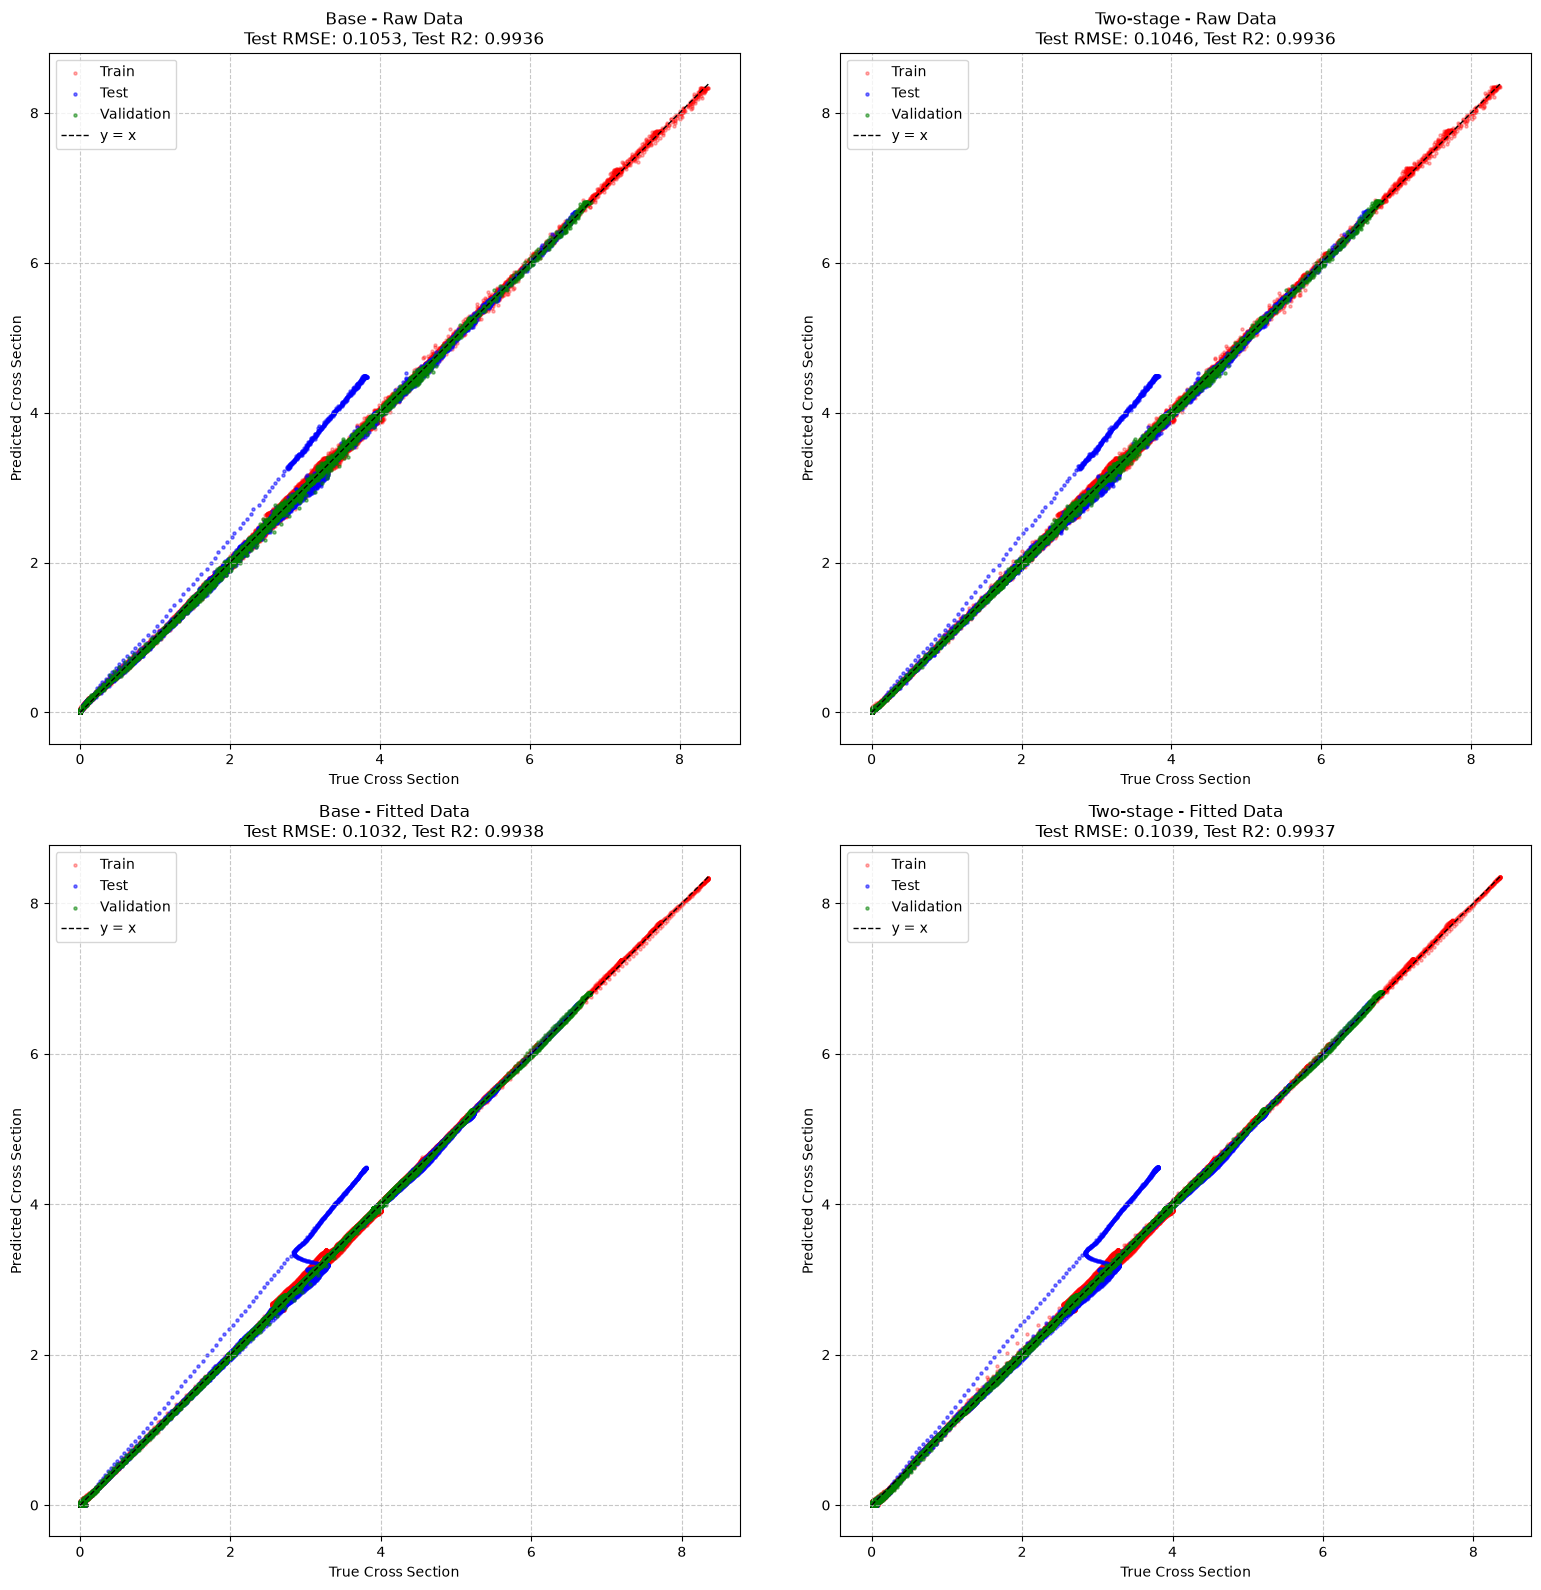

In [11]:
def parity_panel(ax, y_train, p_train, y_test, p_test, y_val, p_val, title):
    p_train = p_train.flatten()
    p_test = p_test.flatten()
    p_val = p_val.flatten()
    ax.scatter(y_train, p_train, s=size, color='red', alpha=0.3, label='Train')
    ax.scatter(y_test, p_test, s=size, color='blue', alpha=0.5, label='Test')
    ax.scatter(y_val, p_val, s=size, color='green', alpha=0.5, label='Validation')
    lo = min(y_train.min(), y_test.min(), y_val.min(), p_train.min(), p_test.min(), p_val.min())
    hi = max(y_train.max(), y_test.max(), y_val.max(), p_train.max(), p_test.max(), p_val.max())
    ax.plot([lo, hi], [lo, hi], 'k--', linewidth=1, label='y = x')
    rmse = np.sqrt(np.mean((y_test - p_test) ** 2))
    r2 = r2_score(y_test, p_test)
    ax.set_title(f"{title}\nTest RMSE: {rmse:.4f}, Test R2: {r2:.4f}")
    ax.set_xlabel('True Cross Section')
    ax.set_ylabel('Predicted Cross Section')
    ax.set_aspect('equal')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.7)

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
parity_panel(axes[0, 0], yraw_selected_train, pretrained_predraw_train,
             yraw_selected_test, pretrained_predraw_test, 
             yraw_selected_val, pretrained_predraw_val, 'Base - Raw Data')
parity_panel(axes[0, 1], yraw_selected_train, fine_tuned_predraw_train,
             yraw_selected_test, fine_tuned_predraw_test, yraw_selected_val, fine_tuned_predraw_val, 'Two-stage - Raw Data')
parity_panel(axes[1, 0], yfit_selected_train, pretrained_predfit_train,
             yfit_selected_test, pretrained_predfit_test, yfit_selected_val, pretrained_predfit_val, 'Base - Fitted Data')
parity_panel(axes[1, 1], yfit_selected_train, fine_tuned_predfit_train,
             yfit_selected_test, fine_tuned_predfit_test, yfit_selected_val, fine_tuned_predfit_val, 'Two-stage - Fitted Data')
plt.tight_layout()
plt.show()


Unique j1 values in raw train data: [ 0.  1.  3.  5.  7.  9. 11. 13. 15. 16.]
Unique j1 values in raw  test data: [ 0.  1.  3.  5.  7.  9. 11. 13. 15. 16.]
Unique j1 values in raw   val data: [ 0.  1.  7.  9. 11. 13. 16.]
Unique j2 values in raw train data: [ 0.  1.  3.  5.  7.  9. 11. 13. 15. 17. 19. 21. 23.]
Unique j2 values in raw  test data: [ 0.  1.  3.  5.  7.  9. 11. 17. 19. 21. 23.]
Unique j2 values in raw   val data: [ 0.  1.  5.  7.  9. 15. 19. 21. 23.]
Unique j1 values in raw data: [ 0.  1.  3.  5.  7.  9. 11. 13. 15. 16.]
Unique j2 values in raw data: [ 0.  1.  3.  5.  7.  9. 11. 13. 15. 17. 19. 21. 23.]
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 270us/step
Plotting for (j1=1, j=11)
Plotting for (j1=3, j=13)


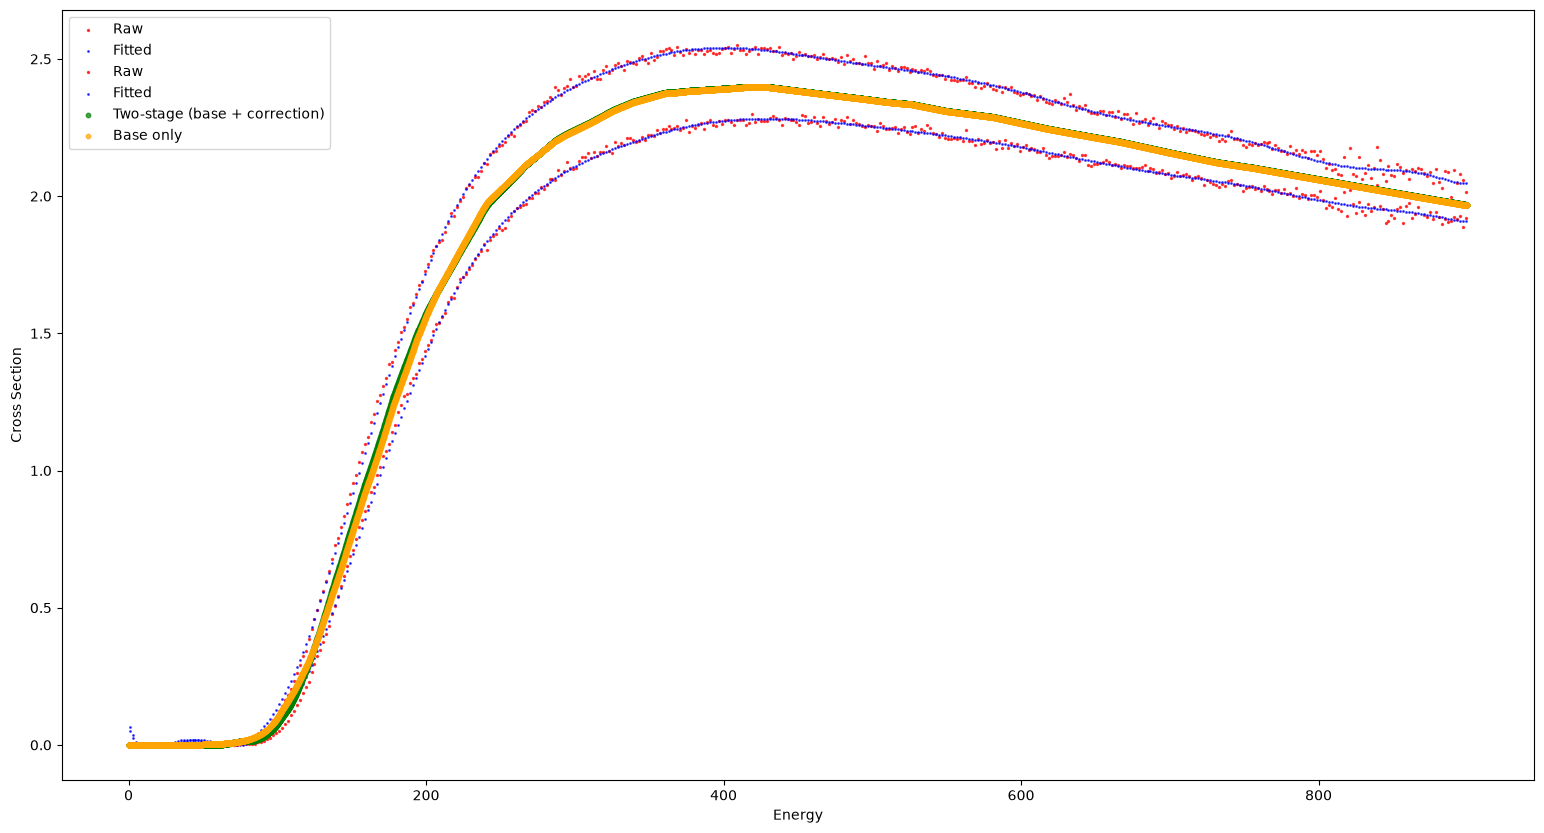

In [12]:

print("Unique j1 values in raw train data:", np.unique(Xraw_selected_train[:, 0]))
print("Unique j1 values in raw  test data:", np.unique(Xraw_selected_test[:, 0]))
print("Unique j1 values in raw   val data:", np.unique(Xraw_selected_val[:, 0]))
print("Unique j2 values in raw train data:", np.unique(Xraw_selected_train[:, 1]))
print("Unique j2 values in raw  test data:", np.unique(Xraw_selected_test[:, 1]))
print("Unique j2 values in raw   val data:", np.unique(Xraw_selected_val[:, 1]))

Xraw = np.concatenate((Xraw_selected_train, \
                       Xraw_selected_test, \
                       Xraw_selected_val), axis=0)
yraw = np.concatenate((yraw_selected_train, \
                       yraw_selected_test, \
                        yraw_selected_val), axis=0)
Xfit = np.concatenate((Xfit_selected_train, \
                       Xfit_selected_test, \
                       Xfit_selected_val), axis=0)
yfit = np.concatenate((yfit_selected_train, \
                       yfit_selected_test, \
                        yfit_selected_val), axis=0)

print("Unique j1 values in raw data:", np.unique(Xraw[:, 0]))
print("Unique j2 values in raw data:", np.unique(Xraw[:, 1]))

j1s= [1, 3]
j1pred = 2
j2s = [11, 13]
j2pred = 12
selectedindex = np.where((Xraw[:, 0] == j1s[0]) \
                         & (Xraw[:, 1] == j2s[0]))
evalues = np.arange(0, 900, 0.1)  # Replace this with the actual energy values you want to use

X_pres = np.array([[j1pred, j2pred, e] for e in evalues])
X_pres_scaled = scalerX.transform(X_pres)
pretrain_predictions = scalery.inverse_transform(pretrained_model.predict(X_pres_scaled).reshape(-1, 1))  # base only
fine_tuned_predictions = predict_two_stage(X_pres_scaled)                                                  # base + correction
#print(f"Predictions for (v={j1pred}, j={j2pred}) at different energies:")
#for e, pred in zip(evalues, predictions.flatten()):
#    print(f"Energy: {e:.2f}, Predicted Target: {pred:.4f}")plt.figure(figsize=(19, 10))
plt.figure(figsize=(19, 10))
for j1,j2 in zip(j1s, j2s):
    print(f"Plotting for (j1={j1}, j={j2})")
    selectedindex = np.where((Xraw[:, 0] == j1) & (Xraw[:, 1] == j2))
    Xraw_subset = Xraw[selectedindex]
    eraw = Xraw_subset[:, 2]
    yraw_subset = yraw[selectedindex]
    plt.scatter(eraw, yraw_subset, s=2, label="Raw", color='red', alpha=0.7)
    selectedindex = np.where((Xfit[:, 0] == j1) & (Xfit[:, 1] == j2))
    Xfit_subset = Xfit[selectedindex]
    efit = Xfit_subset[:, 2]
    yfit_subset = yfit[selectedindex]
    plt.scatter(efit, yfit_subset, s=1, label="Fitted", color='blue', alpha=0.7) 
plt.scatter(evalues, fine_tuned_predictions.flatten(), s=size*2, label="Two-stage (base + correction)", color='green', alpha=0.7)
plt.scatter(evalues, pretrain_predictions.flatten(), s=size*2, label="Base only", color='orange', alpha=0.7)
plt.xlabel('Energy')
plt.ylabel('Cross Section')
plt.legend()
# increase figsize
plt.show()